In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Considere el proyecto cuyo cuadro de prelaciones, duraciones medias y desviaciones típicas (en semanas) se adjunta.

In [4]:
pregunta_1 = "1. Determine la duración media del proyecto y su(s) camino(s) crítico(s).  "
pregunta_2 = "2. Calcule la varianza y la desviación típica de la duración del proyecto. ¿Qué ruta crítica debe usarse para ello? Razone la respuesta.  "
pregunta_3 = "3. ¿Qué probabilidad hay de terminar el proyecto en 21 semanas o menos?  "
pregunta_4 = "4. ¿Qué probabilidad hay de terminar entre las semanas 18 y 21?  "
pregunta_5 = "5. ¿Qué duración puede comprometerse con el cliente con una probabilidad del 90% de cumplirla?  "
pregunta_6 = "6. ¿Qué probabilidad hay de terminar en la duración media o antes? ¿Puede garantizarse esa duración con un 90% de probabilidad sin modificar el proyecto?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Determine la duración media del proyecto y su(s) camino(s) crítico(s).  

2. Calcule la varianza y la desviación típica de la duración del proyecto. ¿Qué ruta crítica debe usarse para ello? Razone la respuesta.  

3. ¿Qué probabilidad hay de terminar el proyecto en 21 semanas o menos?  

4. ¿Qué probabilidad hay de terminar entre las semanas 18 y 21?  

5. ¿Qué duración puede comprometerse con el cliente con una probabilidad del 90% de cumplirla?  

6. ¿Qué probabilidad hay de terminar en la duración media o antes? ¿Puede garantizarse esa duración con un 90% de probabilidad sin modificar el proyecto?  

In [5]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, standard_deviation
    ('A'     , '---'      , 3       , 0.8               ),
    ('B'     , '---'      , 3       , 0.2               ),
    ('C'     , 'A,B'      , 2       , 0.4               ),
    ('D'     , 'C'        , 3       , 0.3               ),
    ('E'     , 'C'        , 2       , 0.8               ),
    ('F'     , 'E'        , 5       , 0.2               ),
    ('G'     , 'D,F'      , 1       , 0.2               ),
    ('H'     , 'F'        , 4       , 0.8               ),
    ('I'     , 'G,H'      , 3       , 0.2               ),
], columns=['activity', 'predecessor', 'duration', 'standard_deviation']).set_index('activity')
datos_enunciado

,predecessor,duration,standard_deviation
activity,,,
A,---,3,0.8
B,---,3,0.2
C,"A,B",2,0.4
D,C,3,0.3
E,C,2,0.8
F,E,5,0.2
G,"D,F",1,0.2
H,F,4,0.8
I,"G,H",3,0.2


El proyecto corresponde a la apertura de una clínica veterinaria; las actividades son las siguientes (las duraciones del cuadro están en semanas).

In [6]:
#| tbl-cap: "Descripción de las actividades"
#| label: tbl-descripciones
descripciones = pd.Series({
    'A': 'Estudio de mercado y local',
    'B': 'Proyecto de reforma y licencia',
    'C': 'Obra de reforma',
    'D': 'Instalación de quirófano y radiología',
    'E': 'Mobiliario y equipamiento clínico',
    'F': 'Software de gestión',
    'G': 'Selección de personal',
    'H': 'Acuerdos con proveedores',
    'I': 'Registro sanitario',
}, name='Descripción')
descripciones.to_frame()

,Descripción
A,Estudio de mercado y local
B,Proyecto de reforma y licencia
C,Obra de reforma
D,Instalación de quirófano y radiología
E,Mobiliario y equipamiento clínico
F,Software de gestión
G,Selección de personal
H,Acuerdos con proveedores
I,Registro sanitario


# Resolución

In [7]:
datos_proyecto = datos_enunciado.copy()
datos_proyecto['variance'] = datos_proyecto['standard_deviation'] ** 2
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()

## Apartado 1

In [8]:
display(Markdown(pregunta_1))

1. Determine la duración media del proyecto y su(s) camino(s) crítico(s).  

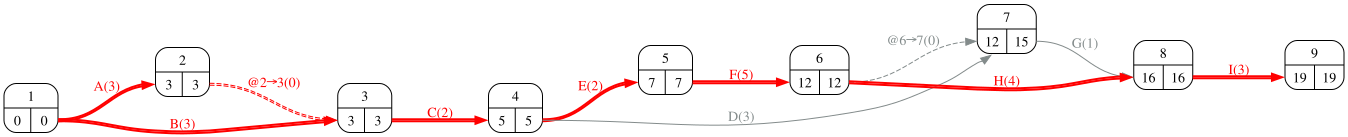

In [9]:
#| fig-cap: "Grafo PERT con tiempos de los nodos y camino crítico"
#| label: fig-pert
proyecto.pert(durations=datos_proyecto['duration'], ranksep=1)

In [10]:
#| tbl-cap: "Holgura total de las actividades"
#| label: tbl-holguras
resultados_pert = proyecto.calculate_pert(durations=datos_proyecto['duration'])
resultados_pert['activities'].T

,@2→3,@6→7,A,B,C,D,E,F,G,H,I
H_total,0,3,0,0,0,7,0,0,3,0,0


In [11]:
duracion_media = proyecto.duration(datos_proyecto['duration'])
rutas_criticas = proyecto.critical_path(datos_proyecto['duration'])
for nombre, acts in rutas_criticas.items():
    print(f'{nombre}: {" - ".join(acts)}')
Markdown(f'La duración media del proyecto es {duracion_media} semanas y tiene {len(rutas_criticas)} ruta(s) crítica(s).')

Route_3: A - C - E - F - H - I
Route_6: B - C - E - F - H - I


La duración media del proyecto es 19 semanas y tiene 2 ruta(s) crítica(s).

## Apartado 2

In [12]:
display(Markdown(pregunta_2))

2. Calcule la varianza y la desviación típica de la duración del proyecto. ¿Qué ruta crítica debe usarse para ello? Razone la respuesta.  

Por el teorema central del límite, la duración de una ruta es aproximadamente normal con media la suma de las medias y varianza la suma de las varianzas de sus actividades. Para el proyecto se toma la ruta crítica; si hay varias, la de mayor varianza, que es la hipótesis más prudente (la verdadera distribución del máximo de varias rutas no es normal, y el método PERT la aproxima así).

In [13]:
#| tbl-cap: "Varianza de las rutas críticas"
#| label: tbl-varianzaRutas
desviacion_proyecto, varianza_rutas = proyecto.standard_deviation(durations=datos_proyecto['duration'],
                                                                   variances=datos_proyecto['variance'])
varianza_rutas

,Activities,Variance
Route_3,"A, C, E, F, H, I",2.16
Route_6,"B, C, E, F, H, I",1.56


Sumando actividad a actividad a lo largo de cada ruta (la media de una ruta es la suma de las medias; su varianza, la suma de las varianzas):

In [14]:
#| tbl-cap: "Media y varianza de cada ruta, sumando sus actividades"
#| label: tbl-rutasPaso
R = proyecto.path_matrix(dummies=False)
detalle_medias = detalle_rutas(R, datos_proyecto['duration'][R.columns], 'media')
detalle_varianzas = detalle_rutas(R, datos_proyecto['variance'][R.columns], 'varianza', 3)
pd.concat([detalle_medias, detalle_varianzas.drop(columns='actividades')], axis=1)

,actividades,media = suma,media,varianza = suma,varianza
Route_1,A - C - D - G - I,A(3) + C(2) + D(3) + G(1) + I(3) = 12,12.0,A(0.640) + C(0.160) + D(0.090) + G(0.040) + I(...,0.97
Route_2,A - C - E - F - G - I,A(3) + C(2) + E(2) + F(5) + G(1) + I(3) = 16,16.0,A(0.640) + C(0.160) + E(0.640) + F(0.040) + G(...,1.56
Route_3,A - C - E - F - H - I,A(3) + C(2) + E(2) + F(5) + H(4) + I(3) = 19,19.0,A(0.640) + C(0.160) + E(0.640) + F(0.040) + H(...,2.16
Route_4,B - C - D - G - I,B(3) + C(2) + D(3) + G(1) + I(3) = 12,12.0,B(0.040) + C(0.160) + D(0.090) + G(0.040) + I(...,0.37
Route_5,B - C - E - F - G - I,B(3) + C(2) + E(2) + F(5) + G(1) + I(3) = 16,16.0,B(0.040) + C(0.160) + E(0.640) + F(0.040) + G(...,0.96
Route_6,B - C - E - F - H - I,B(3) + C(2) + E(2) + F(5) + H(4) + I(3) = 19,19.0,B(0.040) + C(0.160) + E(0.640) + F(0.040) + H(...,1.56


In [15]:
Markdown(f'La varianza del proyecto es {desviacion_proyecto**2:.3f} y su desviación típica {desviacion_proyecto:.3f} semanas.')

La varianza del proyecto es 2.160 y su desviación típica 1.470 semanas.

## Apartado 3

In [16]:
display(Markdown(pregunta_3))

3. ¿Qué probabilidad hay de terminar el proyecto en 21 semanas o menos?  

Con $T \sim N(\mu, \sigma)$: $P(T \le t) = \Phi\left(\frac{t - \mu}{\sigma}\right)$.

In [17]:
plazo = 21
z = (plazo - duracion_media) / desviacion_proyecto
probabilidad_plazo = norm.cdf(z)
Markdown(f'z = ({plazo} − {duracion_media}) / {desviacion_proyecto:.3f} = {z:.3f}, luego P(T ≤ {plazo}) = Φ({z:.3f}) = {probabilidad_plazo:.4f} ({probabilidad_plazo*100:.1f} %).')

z = (21 − 19) / 1.470 = 1.361, luego P(T ≤ 21) = Φ(1.361) = 0.9132 (91.3 %).

## Apartado 4

In [18]:
display(Markdown(pregunta_4))

4. ¿Qué probabilidad hay de terminar entre las semanas 18 y 21?  

In [19]:
t_a, t_b = 18, 21
p_b = norm.cdf((t_b - duracion_media) / desviacion_proyecto)
p_a = norm.cdf((t_a - duracion_media) / desviacion_proyecto)
Markdown(f'P({t_a} < T ≤ {t_b}) = Φ({(t_b - duracion_media) / desviacion_proyecto:.3f}) − Φ({(t_a - duracion_media) / desviacion_proyecto:.3f}) '
         f'= {p_b:.4f} − {p_a:.4f} = {p_b - p_a:.4f} ({(p_b - p_a)*100:.1f} %).')

P(18 < T ≤ 21) = Φ(1.361) − Φ(-0.680) = 0.9132 − 0.2481 = 0.6651 (66.5 %).

## Apartado 5

In [20]:
display(Markdown(pregunta_5))

5. ¿Qué duración puede comprometerse con el cliente con una probabilidad del 90% de cumplirla?  

Se busca $t$ tal que $P(T \le t) = p$, es decir, $t = \mu + z_p\,\sigma$ con $z_p = \Phi^{-1}(p)$.

In [21]:
probabilidad_objetivo = 0.9
z_p = norm.ppf(probabilidad_objetivo)
duracion_comprometida = duracion_media + z_p * desviacion_proyecto
Markdown(f'z = {z_p:.3f}; t = {duracion_media} + {z_p:.3f} × {desviacion_proyecto:.3f} = {duracion_comprometida:.2f} semanas. '
         f'Como el calendario se mide en semanas enteras, se comprometerían {int(np.ceil(duracion_comprometida))} semanas.')

z = 1.282; t = 19 + 1.282 × 1.470 = 20.88 semanas. Como el calendario se mide en semanas enteras, se comprometerían 21 semanas.

## Apartado 6

In [22]:
display(Markdown(pregunta_6))

6. ¿Qué probabilidad hay de terminar en la duración media o antes? ¿Puede garantizarse esa duración con un 90% de probabilidad sin modificar el proyecto?  

In [23]:
Markdown(f'''La duración media es la mediana de la normal, así que P(T ≤ {duracion_media}) = 0.5: sólo la mitad de las veces se terminaría en la duración media o antes. Para garantizarla con un 90% haría falta que la media del proyecto fuera {duracion_media} − {z_p:.3f} × {desviacion_proyecto:.3f} = {duracion_media - z_p * desviacion_proyecto:.2f} semanas, es decir, reducir el proyecto (acortando actividades críticas) o reducir su varianza. Sin tocar el proyecto no es posible.''')

La duración media es la mediana de la normal, así que P(T ≤ 19) = 0.5: sólo la mitad de las veces se terminaría en la duración media o antes. Para garantizarla con un 90% haría falta que la media del proyecto fuera 19 − 1.282 × 1.470 = 17.12 semanas, es decir, reducir el proyecto (acortando actividades críticas) o reducir su varianza. Sin tocar el proyecto no es posible.